## Import e configurazione

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

In [2]:
# --- base
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# --- scikit-learn / xgboost
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [3]:
RS = 42
N_FOLDS = 3     # fold della CV (usati solo per il tuning)
N_ITER_MODEL = {"Logistic regression": 3, "Random forest": 3, "XGBoost": 6, "MLP": 2}   # configurazioni provate per modello

## Caricamento dati

In [4]:
ID_DTYPE = {"collision_index": str}

X_train = pd.read_csv("../00_Data/Input/X_train.csv", dtype=ID_DTYPE)
X_test  = pd.read_csv("../00_Data/Input/X_test.csv",  dtype=ID_DTYPE)
y_train = pd.read_csv("../00_Data/Input/y_train.csv", dtype=ID_DTYPE)
y_test  = pd.read_csv("../00_Data/Input/y_test.csv",  dtype=ID_DTYPE)
sel_features = pd.read_csv("../00_Data/Output/selected_features.csv").iloc[:, 0].tolist()
print("Variabili selezionate:", len(sel_features))

Variabili selezionate: 40


# Confronto tra modelli

## Preparazione dati 

In [5]:
ID = "collision_index"
X_train, X_test = X_train.set_index(ID), X_test.set_index(ID)
y_train, y_test = y_train.set_index(ID), y_test.set_index(ID)
assert (X_train.index == y_train.index).all(), "X_train e y_train non allineati"
assert (X_test.index == y_test.index).all(), "X_test e y_test non allineati"

X_tr = X_train[sel_features].astype("float32").reset_index(drop=True)
X_te = X_test[sel_features].astype("float32").reset_index(drop=True)
y_tr = y_train.squeeze("columns").astype(int).reset_index(drop=True)
y_te = y_test.squeeze("columns").astype(int).reset_index(drop=True)

assert len(X_tr) == len(y_tr) and len(X_te) == len(y_te)
assert set(y_tr.unique()) <= {0, 1}
assert list(X_tr.columns) == list(X_te.columns)
assert not any(ch in c for c in X_tr.columns for ch in "[]<>")   # caratteri non accettati da XGBoost

# variabile di controllo sul sistema di registrazione (IBRS): deve esserci sempre
CONTROL = "collision_injury_based"
assert CONTROL in sel_features, f"{CONTROL} non è tra le variabili selezionate: controlla il 03"
assert set(X_tr[CONTROL].unique()) == {0, 1}, f"{CONTROL} deve essere 0/1 con entrambi i valori presenti"
print(f"{CONTROL}: quota IBRS train {X_tr[CONTROL].mean():.3f} | validation {X_te[CONTROL].mean():.3f}")

print("Train:", X_tr.shape, " Validation:", X_te.shape, f" quota grave train={y_tr.mean():.3f}")

collision_injury_based: quota IBRS train 0.602 | validation 0.601
Train: (359621, 40)  Validation: (154124, 40)  quota grave train=0.242


## Preprocessing
Le dummy (0/1) restano come sono; le colonne non binarie (es. conteggi, eta', limiti di velocita')
vengono standardizzate solo per i modelli sensibili alla scala:

| Modello | Preprocessing | Motivo |
|---|---|---|
| Regressione logistica | StandardScaler sulle non binarie | regolarizzazione L2 dipende dalla scala |
| Random forest | nessuno | gli alberi sono invarianti alla scala |
| XGBoost | nessuno | idem |
| MLP | StandardScaler sulle non binarie | discesa del gradiente converge male con scale diverse |
| Bagging (alberi) | nessuno | alberi |
| Voting | quello di ogni modello interno | ogni pipeline porta il suo preprocessing |

In [6]:
bin_cols = [c for c in X_tr.columns if set(np.unique(X_tr[c])) <= {0, 1}]
num_cols = [c for c in X_tr.columns if c not in bin_cols]
print(f"Dummy: {len(bin_cols)}  |  Non binarie (da scalare): {len(num_cols), num_cols}")

def scaler():
    # scala solo le non binarie, lascia passare le dummy
    return ColumnTransformer([("num", StandardScaler(), num_cols)],
                             remainder="passthrough", verbose_feature_names_out=False)

Dummy: 9  |  Non binarie (da scalare): (31, ['casualty_type_Car', 'vehicle_type_Motorcycle over 125cc', 'latitude', 'age_of_casualty_mean', 'longitude', 'number_of_vehicles', 'number_of_casualties', 'first_point_of_impact_Back', 'vehicle_location_restricted_lane_Main carriageway', 'speed_limit', 'vehicle_manoeuvre_Going ahead', 'skidding_and_overturning_None', 'casualty_class_Driver or rider', 'first_point_of_impact_Front', 'woy', 'sex_of_driver_Male', 'casualty_class_Pedestrian', 'vehicle_type_Pedal cycle', 'vehicle_manoeuvre_Waiting or slowing', 'vehicle_type_Motorcycle up to 125cc', 'vehicle_leaving_carriageway_Nearside', 'junction_location_Not at junction', 'casualty_class_Passenger', 'first_point_of_impact_Side', 'skidding_and_overturning_Overturned', 'sex_of_driver_Female', 'pedestrian_movement_Crossing', 'vehicle_leaving_carriageway_Offside', 'hit_object_off_carriageway_Tree', 'vehicle_manoeuvre_Turning', 'casualty_type_Van'])


## Definizione modelli

In [7]:
def make_models():
    logreg = Pipeline([
        ("prep", scaler()),
        ("model", LogisticRegression(C=1.0, max_iter=2000)),
    ])
    rf = Pipeline([
        ("model", RandomForestClassifier(300, min_samples_leaf=20, n_jobs=-1, random_state=RS)),
    ])
    xgb = Pipeline([
        ("model", XGBClassifier(n_estimators=600, learning_rate=0.01, max_depth=6,
                                subsample=0.8, colsample_bytree=0.8,
                                eval_metric="logloss", tree_method="hist",
                                n_jobs=-1, random_state=RS)),
    ])

    mlp = Pipeline([
        ("prep", scaler()),
        ("model", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, # abbassare hidden layes sizes se pesante
                                early_stopping=True, max_iter=200, random_state=RS)),
    ])
    bag = Pipeline([
        ("model", BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=50),
                                    n_estimators=100, max_samples=0.5,
                                    n_jobs=-1, random_state=RS)),
    ])
    # Soft voting: media delle probabilità dei quattro modelli
    voting = VotingClassifier(
        [("logreg", logreg), ("rf", rf), ("xgb", xgb), ("mlp", mlp)],
        voting="soft", n_jobs=1,
    )
    return {"Logistic regression": logreg, 
            "Random forest": rf, 
            "XGBoost": xgb, 
            "MLP": mlp, 
            "Bagging": bag, 
            "Voting (soft)": voting}

models = make_models()

## Tuning iperparametri modelli

In [8]:
# Trigger per decidere se eseguire il tuning
RUN_CV = True  

folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=RS).split(X_tr, y_tr))

param_grids = {
    "Logistic regression": {
        'model__C': [0.1, 1.0, 10.0],                    
    },
    "Random forest": {
        'model__min_samples_leaf': [20, 30, 50],         
        'model__max_features': ['sqrt'],                
    },
    "XGBoost": {
        'model__n_estimators':     [600],                
        'model__learning_rate':    [0.03, 0.05],
        'model__max_depth':        [8, 10],             
        'model__colsample_bytree': [0.4, 0.5, 0.7],
        'model__min_child_weight': [5, 20, 50],
    },
    "MLP": {
        'model__hidden_layer_sizes': [(128, 64)],        # fissata: in prove precedenti batteva (64, 32)
        'model__alpha': [0.0001, 0.001, 0.01],
    },
}

best_params_dict = {}
tuned_models = {}
searches = {}

if RUN_CV:
    print("-> Tuning con RandomizedSearchCV\n")
    for name, model in models.items():
        if name in param_grids:
            search = RandomizedSearchCV(
                estimator=model,
                param_distributions=param_grids[name],
                n_iter=N_ITER_MODEL[name],
                scoring="roc_auc",
                cv=folds,
                random_state=RS,
                verbose=1,
            )
            search.fit(X_tr, y_tr)
            searches[name] = search
            
            best_params_dict[name] = search.best_params_
            tuned_models[name] = search.best_estimator_
            
            print(f"[{name}] Migliori parametri trovati: {search.best_params_}")
        else:
            tuned_models[name] = model
            best_params_dict[name] = "Nessun tuning (Ensemble/Altro)"
            print(f"[{name}] Saltato il tuning.")

    tuned_models["Voting (soft)"] = VotingClassifier([("logreg", tuned_models["Logistic regression"]), 
                                                      ("rf", tuned_models["Random forest"]),
                                                      ("xgb", tuned_models["XGBoost"]), 
                                                      ("mlp", tuned_models["MLP"])],
                                                      voting="soft", n_jobs=1)

    models = tuned_models
    print("\n" + "="*50 + "\n")
else:
    print("-> Tuning disattivato (RUN_CV = False). Utilizzo dei modelli con parametri attuali.")

-> Tuning con RandomizedSearchCV

Fitting 3 folds for each of 3 candidates, totalling 9 fits
[Logistic regression] Migliori parametri trovati: {'model__C': 10.0}
Fitting 3 folds for each of 3 candidates, totalling 9 fits
[Random forest] Migliori parametri trovati: {'model__min_samples_leaf': 20, 'model__max_features': 'sqrt'}
Fitting 3 folds for each of 6 candidates, totalling 18 fits
[XGBoost] Migliori parametri trovati: {'model__n_estimators': 600, 'model__min_child_weight': 50, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}
Fitting 3 folds for each of 2 candidates, totalling 6 fits
[MLP] Migliori parametri trovati: {'model__hidden_layer_sizes': (128, 64), 'model__alpha': 0.0001}
[Bagging] Saltato il tuning.
[Voting (soft)] Saltato il tuning.




In [9]:
print("Iperparametri scelti dal tuning:")
for name, params in best_params_dict.items():
    print(f"- {name}: {params}")

Iperparametri scelti dal tuning:
- Logistic regression: {'model__C': 10.0}
- Random forest: {'model__min_samples_leaf': 20, 'model__max_features': 'sqrt'}
- XGBoost: {'model__n_estimators': 600, 'model__min_child_weight': 50, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}
- MLP: {'model__hidden_layer_sizes': (128, 64), 'model__alpha': 0.0001}
- Bagging: Nessun tuning (Ensemble/Altro)
- Voting (soft): Nessun tuning (Ensemble/Altro)


## Fit sul training completo e valutazione sul validation

Logistic regression    AUC 0.7242
Random forest          AUC 0.7495
XGBoost                AUC 0.7562
MLP                    AUC 0.7460
Bagging                AUC 0.7438
Voting (soft)          AUC 0.7525


,modello,roc_auc
0,XGBoost,0.7562
1,Voting (soft),0.7525
2,Random forest,0.7495
3,MLP,0.7460
4,Bagging,0.7438
5,Logistic regression,0.7242


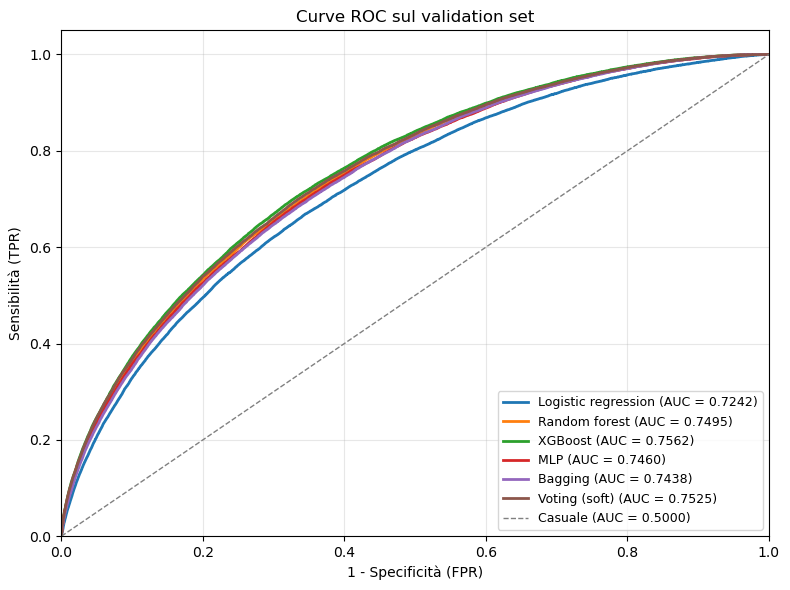

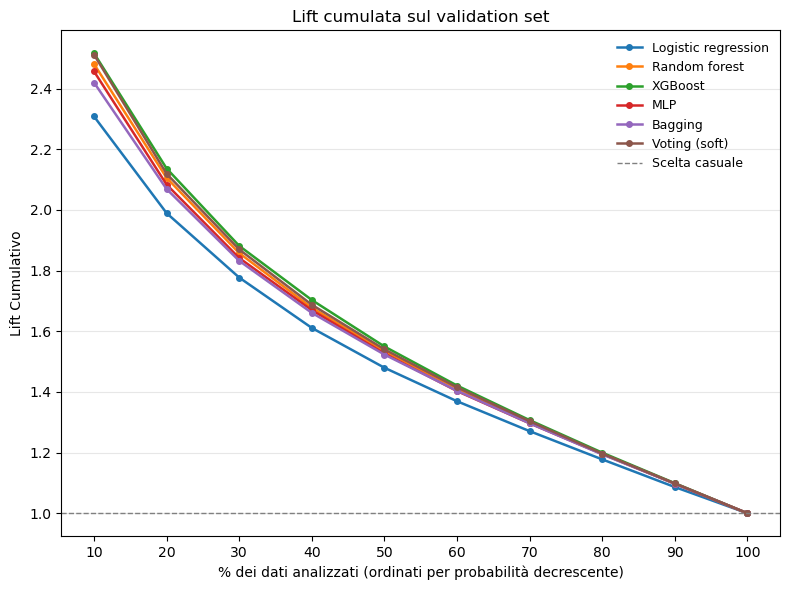

In [10]:
fitted, probs = {}, {}

# --- 1. FIT SUL TRAIN E PROBABILITA' SUL VALIDATION ---
for name, model in models.items():
    m = clone(model).fit(X_tr, y_tr)
    fitted[name] = m
    probs[name] = m.predict_proba(X_te)[:, 1]
    print(f"{name:22s} AUC {roc_auc_score(y_te, probs[name]):.4f}")

test_res = (pd.DataFrame({"modello": list(probs), "roc_auc": [roc_auc_score(y_te, p) for p in probs.values()]})
              .sort_values("roc_auc", ascending=False).reset_index(drop=True))
display(test_res.round(4))

# --- 2. CURVE ROC SOVRAPPOSTE ---
plt.figure(figsize=(8, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_te, p):.4f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1, ls="--", label="Casuale (AUC = 0.5000)")
plt.xlim(0, 1); plt.ylim(0, 1.05)
plt.xlabel("1 - Specificità (FPR)"); plt.ylabel("Sensibilità (TPR)")
plt.title("Curve ROC sul validation set")
plt.legend(loc="lower right", fontsize=9); plt.grid(alpha=0.3)
plt.savefig("../02_Output_grafici/04_roc_validation.png", dpi=300, bbox_inches="tight")
plt.tight_layout(); plt.show()

# --- 3. LIFT CUMULATA ---
def lift_table(y, p, n_bins=10):
    df = (pd.DataFrame({"y": np.asarray(y).ravel(), "p": p})
            .sort_values("p", ascending=False, kind="mergesort").reset_index(drop=True))
    df["decile"] = np.arange(len(df)) * n_bins // len(df) + 1
    base = df["y"].mean()
    g = df.groupby("decile").agg(n=("y", "size"), gravi=("y", "sum"))
    g["lift_cum"] = g["gravi"].cumsum() / g["n"].cumsum() / base    # teniamo solo la cumulata
    return g

lifts = {n: lift_table(y_te, p) for n, p in probs.items()}
x = lifts[next(iter(lifts))].index * 10                             

plt.figure(figsize=(8, 6))
for name, t in lifts.items():
    plt.plot(x, t["lift_cum"], marker="o", ms=4, lw=1.8, label=name)

plt.axhline(1, color="gray", lw=1, ls="--", label="Scelta casuale")
plt.title("Lift cumulata sul validation set")
plt.xticks(x)
plt.xlabel("% dei dati analizzati (ordinati per probabilità decrescente)")
plt.ylabel("Lift Cumulativo")
plt.grid(axis="y", alpha=0.3)
plt.legend(frameon=False, fontsize=9, loc="upper right")
plt.savefig("../02_Output_grafici/04_lift_validation.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [11]:
## Training vs validation: controllo overfitting (regola delle slide: scarto ASE < 5-7%)

ase = lambda y, p: np.mean((np.asarray(y) - p) ** 2)    # ASE = Brier score

rows = []
for name, m in fitted.items():
    p_tr = m.predict_proba(X_tr)[:, 1]
    p_va = probs[name]
    ase_tr, ase_va = ase(y_tr, p_tr), ase(y_te, p_va)
    rows.append({
        "modello":    name,
        "AUC_train":  roc_auc_score(y_tr, p_tr),
        "AUC_valid":  roc_auc_score(y_te, p_va),
        "ASE_train":  ase_tr,
        "ASE_valid":  ase_va,
        "scarto_ASE_%": (ase_va - ase_tr) / ase_tr * 100,
    })

overfit = pd.DataFrame(rows).set_index("modello").sort_values("AUC_valid", ascending=False)
overfit["overfitting"] = np.where(overfit["scarto_ASE_%"] > 7, "sì", "no")
display(overfit.round(4))

,AUC_train,AUC_valid,ASE_train,ASE_valid,scarto_ASE_%,overfitting
modello,,,,,,
XGBoost,0.7807,0.7562,0.1478,0.1536,3.9261,no
Voting (soft),0.7828,0.7525,0.1489,0.1546,3.8723,no
Random forest,0.8252,0.7495,0.1419,0.1559,9.8675,sì
MLP,0.7625,0.7460,0.1523,0.1561,2.4931,no
Bagging,0.7844,0.7438,0.1492,0.1569,5.1403,no
Logistic regression,0.7243,0.7242,0.1618,0.1612,-0.3497,no


# Modello migliore

## Salvataggio

In [12]:
## Salvataggio modelli e risultati
MODEL_DIR = Path("../00_Data/Modelli")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "features":         list(X_tr.columns),   # per controllare al caricamento
    "searches":         searches,             # Random Search completa (cv_results_, best_params_, ...)
    "best_params_dict": best_params_dict,
    "models":           models,               # modelli tunati (non allenati)
    "fitted":           fitted,               # modelli allenati sul train
    "probs":            probs,                # probabilità sul validation
}, MODEL_DIR / "modelli_04.joblib", compress=3)
print("Salvato in", MODEL_DIR / "modelli_04.joblib")

Salvato in ../00_Data/Modelli/modelli_04.joblib


## Caricamento

In [13]:
## Caricamento modelli salvati (eseguire al posto di tuning e fit)
saved = joblib.load(Path("../00_Data/Modelli/modelli_04.joblib"))
assert saved["features"] == list(X_tr.columns), "Le feature sono cambiate: riesegui tuning e fit"

searches         = saved["searches"]
best_params_dict = saved["best_params_dict"]
models           = saved["models"]
fitted           = saved["fitted"]
probs            = saved["probs"]
print("Caricati:", list(fitted))

Caricati: ['Logistic regression', 'Random forest', 'XGBoost', 'MLP', 'Bagging', 'Voting (soft)']


## Scelta della soglia

In [14]:
best = max(probs, key=lambda n: roc_auc_score(y_te, probs[n]))   # miglior AUC sul validation
print("Modello migliore:", best)
p_te = probs[best]                                           # predizioni sul validation
y = np.asarray(y_te).ravel()
P, N = (y == 1).sum(), (y == 0).sum()

# ---- Soglie scelte sul validation (L7, criterio statistico)
RECALL_TARGET = 0.75
fpr_v, tpr_v, thr_v = roc_curve(y, p_te)
acc_v = (tpr_v * P + (1 - fpr_v) * N) / len(y)
t_acc = thr_v[np.argmax(acc_v)]                              # massima accuratezza

prec_v, rec_v, thr_pr = precision_recall_curve(y, p_te)
t_rec = thr_pr[rec_v[:-1] >= RECALL_TARGET].max()           # soglia più alta con recall >= 80%

SOGLIE = {"Accuracy max": t_acc, f"recall >= {RECALL_TARGET:.0%}": t_rec, "0.5": 0.5}
COL = dict(zip(SOGLIE, ["#000000", "#e377c2", "#7f7f7f"]))

def at(y, p, t):
    yp = p >= t
    tp = int((yp & (y == 1)).sum()); fp = int((yp & (y == 0)).sum())
    fn = int(((~yp) & (y == 1)).sum()); tn = int(((~yp) & (y == 0)).sum())
    rec = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); prec = tp / max(tp + fp, 1)
    return {
        "soglia": t, "recall": rec, "precision": prec, "specificity": spec,
        "F1": 2 * prec * rec / max(prec + rec, 1e-12), "accuracy": (tp + tn) / len(y),
        "quota_pred_grave": yp.mean(), "TP": tp, "FP": fp, "FN": fn, "TN": tn
    }

tab = pd.DataFrame([{"criterio": k, **at(y, p_te, t)} for k, t in SOGLIE.items()]).set_index("criterio")
display(tab.round(3))

# ---- Tooltip con matrice in % (sulla riga), precision, F1, specificità
def cdata(fpr, tpr, thr):
    fpr, tpr, thr = map(np.atleast_1d, (fpr, tpr, thr))
    TP = tpr * P; FP = fpr * N                      
    prec = np.where(TP + FP > 0, TP / np.maximum(TP + FP, 1e-12), 0.0)
    f1 = 2 * prec * tpr / np.maximum(prec + tpr, 1e-12)
    return np.column_stack([thr, tpr * 100, (1 - tpr) * 100, fpr * 100, (1 - fpr) * 100, prec, f1, 1 - fpr])

HOVER = ("<b>soglia %{customdata[0]:.3f}</b><br>"
         "─────────────────────<br>"
         "Actual grave:  TP %{customdata[1]:.1f}%  |  FN %{customdata[2]:.1f}%<br>"
         "Actual lieve:  FP %{customdata[3]:.1f}%  |  TN %{customdata[4]:.1f}%<br>"
         "─────────────────────<br>"
         "recall %{y:.3f}  |  specificità %{customdata[7]:.3f}<br>"
         "precision %{customdata[5]:.3f}  |  F1 %{customdata[6]:.3f}<extra></extra>")

# ---- Grafico
fpr, tpr, thr_roc = roc_curve(y, p_te)
thr_roc = np.where(np.isinf(thr_roc), 1.0, thr_roc)         
curve = pd.DataFrame([at(y, p_te, t) for t in np.linspace(0.02, 0.80, 120)])

fig_thr = make_subplots(
    rows=1, cols=2, horizontal_spacing=0.10,
    subplot_titles=(f"ROC (validation) - AUC {roc_auc_score(y, p_te):.3f}", "Metriche vs soglia (validation)")
)

# Sinistra: ROC con matrice nel tooltip
fig_thr.add_trace(go.Scatter(
    x=fpr, y=tpr, mode="lines", name="ROC", 
    line=dict(width=2.5, color="#333333"),
    customdata=cdata(fpr, tpr, thr_roc), hovertemplate=HOVER
), row=1, col=1)

fig_thr.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1], mode="lines", 
    line=dict(dash="dash", color="grey"), showlegend=False, hoverinfo="skip"
), row=1, col=1)

for k, t in SOGLIE.items():
    fx, fy = 1 - tab.loc[k, "specificity"], tab.loc[k, "recall"]
    fig_thr.add_trace(go.Scatter(
        x=[fx], y=[fy], mode="markers",
        marker=dict(size=13, symbol="star", color=COL[k], line=dict(width=1, color="white")),
        name=f"{k}: {t:.3f}", customdata=cdata(fx, fy, t), hovertemplate=HOVER
    ), row=1, col=1)

# Destra: precision / recall / F1 / accuracy vs soglia
for nm, c in [("precision", "#2a78d6"), ("recall", "#eb6834"), ("specificity", "#d62728"),
              ("F1", "#1baf7a"), ("accuracy", "#9467bd")]:
    fig_thr.add_trace(go.Scatter(
        x=curve["soglia"], y=curve[nm], mode="lines", name=nm,
        line=dict(color=c, width=2),
        hovertemplate=f"{nm} %{{y:.3f}}<br>soglia %{{x:.3f}}<extra></extra>"
    ), row=1, col=2)

for k, t in SOGLIE.items():
    fig_thr.add_vline(x=t, line=dict(color=COL[k], dash="dot"), row=1, col=2)

fig_thr.update_xaxes(title_text="FPR (1 - specificità)", row=1, col=1)
fig_thr.update_yaxes(title_text="TPR (recall)", row=1, col=1)
fig_thr.update_xaxes(title_text="soglia", row=1, col=2)
fig_thr.update_yaxes(range=[0, 1.02], row=1, col=2)
fig_thr.update_layout(
    height=520, width=1200, template="plotly_white", hovermode="closest",
    hoverlabel=dict(align="left", font=dict(family="monospace", size=13)),
    title=f"{best} - Soglie scelte sul validation",
    legend=dict(orientation="h", y=-0.22)
)
fig_thr.write_image("../02_Output_grafici/04_soglia_roc_metriche.png", scale=2)
fig_thr.show()

Modello migliore: XGBoost


,soglia,recall,precision,specificity,F1,accuracy,quota_pred_grave,TP,FP,FN,TN
criterio,,,,,,,,,,,
Accuracy max,0.504,0.227,0.626,0.957,0.333,0.781,0.087,8437,5033,28723,111931
recall >= 75%,0.221,0.750,0.383,0.617,0.507,0.649,0.472,27870,44835,9290,72129
0.5,0.500,0.232,0.623,0.955,0.338,0.781,0.090,8607,5217,28553,111747


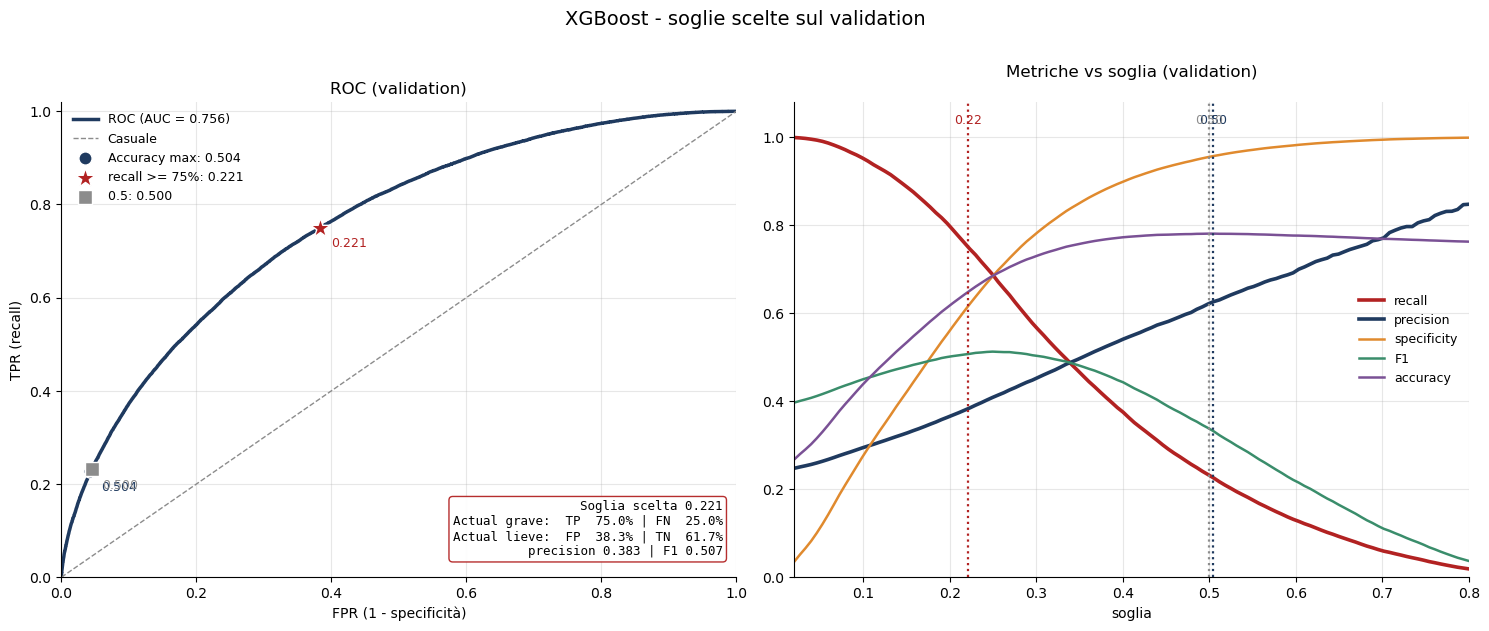

In [15]:
# ---- Grafico statico
NAVY, RED, GREY = "#1F3A5F", "#B22222", "#8C8C8C"
COL = dict(zip(SOGLIE, [NAVY, RED, GREY]))                 # accuracy max, recall target, 0.5
MARK = dict(zip(SOGLIE, ["o", "*", "s"]))
COL_MET = {"recall": RED, "precision": NAVY,               # altre metriche: colori distinti
           "specificity": "#E08A2E", "F1": "#3A8D6B", "accuracy": "#7A5195"}

fpr, tpr, _ = roc_curve(y, p_te)
curve = pd.DataFrame([at(y, p_te, t) for t in np.linspace(0.02, 0.80, 120)])

fig_thr, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.2))

# Sinistra: ROC con le soglie
ax1.plot(fpr, tpr, color=NAVY, lw=2.5, label=f"ROC (AUC = {roc_auc_score(y, p_te):.3f})")
ax1.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--", label="Casuale")
for k, t in SOGLIE.items():
    fx, fy = 1 - tab.loc[k, "specificity"], tab.loc[k, "recall"]
    ax1.scatter(fx, fy, s=220 if MARK[k] == "*" else 90, marker=MARK[k], color=COL[k],
                edgecolor="white", linewidth=1, zorder=5, label=f"{k}: {t:.3f}")
    ax1.annotate(f"{t:.3f}", (fx, fy), xytext=(8, -14), textcoords="offset points",
                 fontsize=9, color=COL[k])

# riquadro con la matrice (in % sulla riga) della soglia scelta
k_sel = f"recall >= {RECALL_TARGET:.0%}"
r = tab.loc[k_sel]
box = (f"Soglia scelta {r['soglia']:.3f}\n"
       f"Actual grave:  TP {r['recall']*100:5.1f}% | FN {(1-r['recall'])*100:5.1f}%\n"
       f"Actual lieve:  FP {(1-r['specificity'])*100:5.1f}% | TN {r['specificity']*100:5.1f}%\n"
       f"precision {r['precision']:.3f} | F1 {r['F1']:.3f}")
ax1.text(0.98, 0.04, box, transform=ax1.transAxes, ha="right", va="bottom", family="monospace",
         fontsize=9, bbox=dict(boxstyle="round", facecolor="white", edgecolor=RED, alpha=0.95))

ax1.set_xlim(0, 1); ax1.set_ylim(0, 1.02)
ax1.set_xlabel("FPR (1 - specificità)"); ax1.set_ylabel("TPR (recall)")
ax1.set_title("ROC (validation)")
ax1.legend(loc="upper left", fontsize=9, frameon=False)
ax1.grid(alpha=0.3)

# Destra: metriche vs soglia
for nm, c in COL_MET.items():
    ax2.plot(curve["soglia"], curve[nm], color=c, lw=2.6 if nm in ("recall", "precision") else 1.8,
             label=nm)
for k, t in SOGLIE.items():
    ax2.axvline(t, color=COL[k], ls=":", lw=1.6)
    ax2.text(t, 1.03, f"{t:.2f}", color=COL[k], ha="center", fontsize=9)
ax2.set_xlim(curve["soglia"].min(), curve["soglia"].max()); ax2.set_ylim(0, 1.08)
ax2.set_xlabel("soglia"); ax2.set_title("Metriche vs soglia (validation)", pad=18)
ax2.legend(loc="center right", fontsize=9, frameon=False)
ax2.grid(alpha=0.3)

for ax in (ax1, ax2):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig_thr.suptitle(f"{best} - soglie scelte sul validation", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("../02_Output_grafici/04_soglia_roc_metriche.png", dpi=300, bbox_inches="tight")
plt.show()

## Matrice con soglia scelta

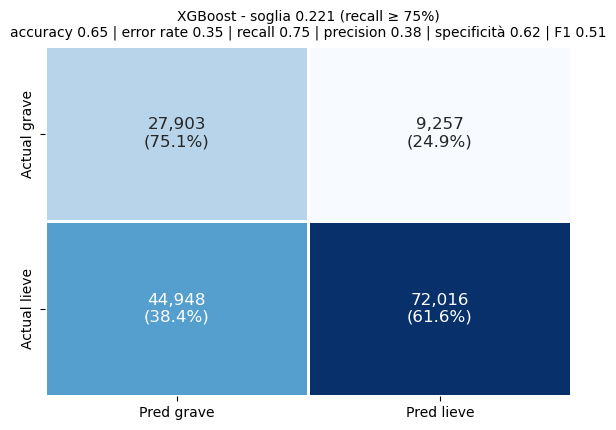

In [16]:
# Matrice di confusione con soglia scelta
# Criterio statistico (L7): per il centralino l'errore più grave è il falso negativo
# (incidente grave classificato lieve) -> soglia più alta che garantisce recall >= 80% sul validation
THR = round(float(t_rec), 3)
p = probs[best]
y = np.asarray(y_te).ravel()
yp = (p >= THR).astype(int)

tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
cm = pd.DataFrame([[tp, fn], [fp, tn]],
                  index=["Actual grave", "Actual lieve"],
                  columns=["Pred grave", "Pred lieve"])

pct = cm.div(cm.sum(axis=1), axis=0) * 100
annot = cm.astype(int).map("{:,}".format) + "\n(" + pct.round(1).astype(str) + "%)"

rec  = tp / max(tp + fn, 1)
prec = tp / max(tp + fp, 1)
spec = tn / max(tn + fp, 1)
f1   = 2 * prec * rec / max(prec + rec, 1e-12)
acc  = (tp + tn) / (tp + tn + fp + fn)
err  = 1 - acc                                    # error rate (priors = proporzioni del campione)

plt.figure(figsize=(5.8, 4.4))
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False,
            linewidths=1, linecolor="white", annot_kws={"size": 12})
plt.title(f"{best} - soglia {THR} (recall ≥ {RECALL_TARGET:.0%})\n"
          f"accuracy {acc:.2f} | error rate {err:.2f} | recall {rec:.2f} | "
          f"precision {prec:.2f} | specificità {spec:.2f} | F1 {f1:.2f}",
          fontsize=10)
plt.tight_layout()
plt.savefig("../02_Output_grafici/04_matrice_confusione.png", dpi=300, bbox_inches="tight")
plt.show()

## Feature importance

- **weight**	quante volte la variabile viene usata per uno split, in tutti gli alberi	premia le variabili continue con tanti valori (latitude, woy), anche se ogni split migliora poco
- **gain**	di quanto migliora in media la loss ogni volta che la variabile viene usata per uno split	misura la qualità dello split, non la frequenza; può gonfiare variabili usate poche volte ma con split molto forti

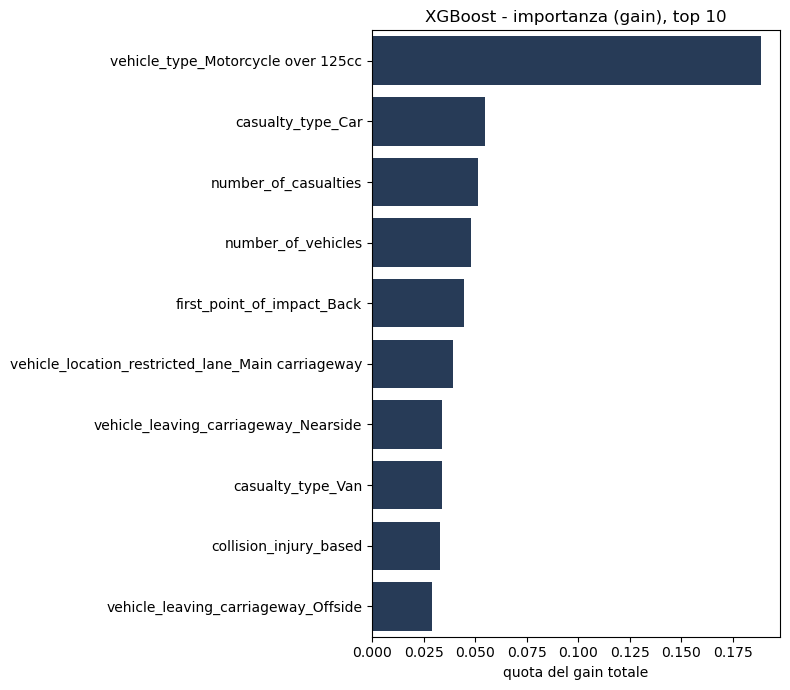

In [17]:
# Feature importance del modello migliore
TOP = 10
NAVY = "#1F3A5F"
feat = X_tr.columns

# --- 1. Gain di XGBoost (solo se il migliore è XGBoost)
if best == "XGBoost":
    m_best = fitted[best].named_steps["model"]
    imp_gain = (pd.Series(m_best.get_booster().get_score(importance_type="gain"))
                  .reindex(feat).fillna(0))
    imp_gain = (imp_gain / imp_gain.sum()).sort_values(ascending=False)

    plt.figure(figsize=(8, 7))
    sns.barplot(x=imp_gain.head(TOP).values, y=imp_gain.head(TOP).index, color=NAVY)
    plt.title(f"{best} - importanza (gain), top {TOP}")
    plt.xlabel("quota del gain totale"); plt.ylabel("")
    plt.tight_layout()
    plt.savefig("../02_Output_grafici/04_importanza_gain.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print(f"Importanza per gain disponibile solo per XGBoost (migliore: {best}): vedi permutation importance")

# Scoring

In [18]:
## Score di nuovi casi (step 4)

def score(X_new, model=fitted[best], thr=THR):
    """Probabilità di collisione grave e classe prevista con la soglia scelta."""
    X_new = X_new[X_tr.columns].astype("float32")
    p = model.predict_proba(X_new)[:, 1]
    return pd.DataFrame({"p_grave": p, "decisione": np.where(p >= thr, "Fatal/Serious", "Slight")},
                        index=X_new.index)

# Score dataset: il validation trattato come insieme di nuove chiamate
scored = score(X_te)
scored.index = X_test.index                                         # collision_index originale
scored.to_csv("../00_Data/Output/score_validation.csv")

# Riepilogo delle decisioni
display(scored["decisione"].value_counts(normalize=True).mul(100).round(1).rename("% chiamate"))

# Esempi per il report: le 5 chiamate con probabilità più alta e le 5 più bassa
display(scored.sort_values("p_grave", ascending=False).head(5).round(3))
display(scored.sort_values("p_grave").head(5).round(3))

decisione
Slight           52.7
Fatal/Serious    47.3
Name: % chiamate, dtype: float64

,p_grave,decisione
collision_index,,
202260B048085,0.971,Fatal/Serious
2025546592225,0.951,Fatal/Serious
2025041626166,0.944,Fatal/Serious
2022031184427,0.941,Fatal/Serious
2022531190920,0.938,Fatal/Serious


,p_grave,decisione
collision_index,,
2022010354978,0.003,Slight
2022010357949,0.003,Slight
2023010441507,0.004,Slight
2024010493897,0.004,Slight
2022010378312,0.004,Slight


## Salvataggio modello per dashboard

In [19]:
import joblib, json
from pathlib import Path

Path("00_Data/Models").mkdir(parents=True, exist_ok=True)

bundle = {
    "model": best_model,                      # già fittato sul train
    "threshold": float(best_thr),             # soglia scelta (recall > 0.8)
    "features": X_train.columns.tolist(),     # ordine esatto delle colonne
    "defaults": X_train.median(numeric_only=True).to_dict(),  # per i campi non compilati
    "metrics_val": {"auc": auc_val, "recall": rec_val, "tnr": tnr_val},
}
joblib.dump(bundle, "00_Data/Models/best_model_bundle.joblib")

NameError: name 'best_model' is not defined